# DSA211: Diagnosing and Remedying Nonlinearity in Bike-Sharing Demand Models
## Notebook 03: Baseline Model & Failure Diagnosis
**Group 2**: Kok Wai Ying, Lee Sin Yang, Lim Wei Lun Marcus, Samuel Teo Yuzhen, Tee Jing Yuan

> **AI Coding Assistant Declaration**:
> In accordance with course guidelines, an AI coding assistant was used strictly for code scaffolding and plotting functions. All modeling decisions, interpretations, and written commentaries are independently authored by group members in the designated sections below (see [`agents.md`](../agents.md)).


### Planned Steps & Workflow (Referencing `docs/project_cv_workflow.html`)
**Model ladder rung: M1 (Base OLS)**
- **1. Setup & Ingestion**:
  - Load the base processed training dataset (`data/train_base.csv`) from Notebook 02.
  - Connect to shared expanding-window CV splits ($k=8$ monthly folds) and fixed evaluation metric.
- **2. Base Model Fit (M1)**:
  - Fit OLS on raw `cnt` with dummy-encoded `hr`, `mnth`, `weekday`, `weathersit`, binary `yr`, `holiday`, `workingday`, and linear `temp`, `hum`, `windspeed`.
  - Report coefficients, $R^2$, Adjusted $R^2$, overall F-test, and RSE.
- **3. Multicollinearity & Rank Check (VIF)**:
  - The base design matrix is rank-deficient: `workingday` is an exact linear combination of the `weekday` dummies and `holiday` (50 columns incl. intercept, rank 49).
  - Check VIF table and document the remedy.
- **4. Nonlinearity Diagnostics**:
  - *Residuals vs. Fitted*: Check for remaining systematic patterns.
  - *Residuals by Hour × Working Day*: Check whether a single hourly profile fits both working days and weekends.
- **5. Added-Variable Plots for Continuous Predictors (Feedback #7)**:
  - Inspect partial regression slopes for `temp`, `hum`, and `windspeed` to detect curvature and threshold effects.
- **6. Heteroskedasticity & Residual Normality Diagnostics**:
  - *Scale-Location plot*: Identify the variance funnel (heteroskedasticity).
  - *Q-Q plot*: Check heavy-tail departures from normality.
- **7. Negative Prediction Violations**:
  - Count and identify hours predicting impossible negative demand ($\hat{y} < 0$).
- **8. Outlier Screening & Date-Based Adjudication (Feedback #5)**:
  - Flag Cook's Distance ($> 4/N$) and group by `dteday` to check known external events.
- **9. Shared Expanding-Window CV Evaluation (Workflow Step 5)**:
  - Evaluate M1 on shared CV folds; record mean CV error and $\text{SE} = \text{SD} / \sqrt{8}$.
- **10. Catalog of Diagnosed Mistakes to Fix in Notebook 04**:
  - List the failures (interactions, curvature, heteroskedasticity, negative counts) to be remedied next.

## 1. Setup and Environment Initialization
*Code: Generated by AI Assistant*

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import scipy.stats as stats
import warnings

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.sm_exceptions import PerfectSeparationWarning

# Ensure local source modules can be imported
sys.path.append(os.path.abspath('..'))
from src.data_utils import load_train_base, BASE_TRAIN_PATH
from src.cv_utils import get_cv_splitter, FIRST_VAL_MONTH, LAST_VAL_MONTH

# Styling
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

# Load data
base_df = load_train_base()
print(f"Base training set loaded. Shape: {base_df.shape}")

# Define columns
ID_COLS = ['dteday']
TARGET = 'cnt'
FEATURE_COLS = [c for c in base_df.columns if c not in ID_COLS + [TARGET]]

# CV Splitter
cv_splitter = get_cv_splitter(base_df['dteday'])
K = cv_splitter.get_n_splits()
print(f"Shared CV Splitter: ExpandingWindowSplit ({K} monthly folds, {FIRST_VAL_MONTH} to {LAST_VAL_MONTH})")
print(f"Predictors: {len(FEATURE_COLS)} | Target: {TARGET}")

Base training set loaded. Shape: (15211, 51)
Shared CV Splitter: ExpandingWindowSplit (8 monthly folds, 2012-02 to 2012-09)
Predictors: 49 | Target: cnt


Breakdown of 49 Predictors:
1. **Dummy variables (43 columns)**
    * `hr` (23 columns) - Reference: Hour 0
    * `mnth` (11 columns) - Reference: January
    * `weekday` (6 columns) - Reference: Sunday
    * `weathersit` (3 columns) - Reference: Clear weather

2. **Binary Flags (3 columns)**
    * `yr`: 0 for 2011, 1 for 2012
    * `holiday`: 1 if holiday, 0 otherwise
    * `workingday`: 0 for holiday/weekend, 1 otherwise

3. **Continuous / Numeric Features (3 columns)**
    * `temp`: Normalized temperature
    * `hum`: Normalized humidity
    * `windspeed`: Normalized wind speed

## 2. Model 1: Base Model Fit On OLS
*Code: Generated by AI Assistant*

In [2]:
# Setup X and y
X = base_df[FEATURE_COLS]
y = base_df[TARGET]
X_const = sm.add_constant(X)

# Fit OLS (suppressing the singular matrix warning so it doesn't spam the screen)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    m1_model = sm.OLS(y, X_const).fit()

# Print your custom stats first
print("=== M1 Base OLS Key Stats ===")
print(f"R-squared:     {m1_model.rsquared:.4f}")
print(f"Adj R-squared: {m1_model.rsquared_adj:.4f}")
print(f"F-statistic:   {m1_model.fvalue:.2f}")
print(f"RSE (Error):   {np.sqrt(m1_model.mse_resid):.2f}")
print(f"Condition No.: {m1_model.condition_number:.2e}")

# Print the FULL summary table below it
print("\n=== Full OLS Summary Table ===")
print(m1_model.summary())

=== M1 Base OLS Key Stats ===
R-squared:     0.6891
Adj R-squared: 0.6881
F-statistic:   700.09
RSE (Error):   99.36
Condition No.: 2.81e+14

=== Full OLS Summary Table ===
                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.689
Model:                            OLS   Adj. R-squared:                  0.688
Method:                 Least Squares   F-statistic:                     700.1
Date:                Sun, 08 Nov 2026   Prob (F-statistic):               0.00
Time:                        19:17:13   Log-Likelihood:                -91511.
No. Observations:               15211   AIC:                         1.831e+05
Df Residuals:                   15162   BIC:                         1.835e+05
Df Model:                          48                                         
Covariance Type:            nonrobust                                         
                   coef    std err   

### Interpretation
**Author**: Kok Wai Ying 
<!-- Document rationale for dropped variables -->

1. The model yields $R^2 = 0.689$ and Adjusted $R^2 = 0.688$, indicating that the linear combination of raw predictors explains approximately 68.9% of the variance in hourly bike demand (cnt). The remaining 31.1% unexplained variance stems from unmodeled nonlinearities, interaction effects, and inherent count variability.
2. The overall F-test is statistically significant ($F = 700.09$, $p < 0.001$), confirming that the predictors collectively hold significant explanatory power over a mean-only baseline model.
3.  From notebook 01 EDA, the mean of overall bike distribution rental is 185.23, however the RSE of 99.36 bikes/hour is a typical in-sample residual size, about 54% of the mean demand of 185.23 (Notebook 01),reflecting substantial absolute prediction uncertainty in this naive baseline.
4. Negative Intercept: The negative intercept (−68.92) is the fitted value for the reference profile (January, hour 0, Sunday, clear weather, with temp = hum = windspeed = 0), which is outside the observed range, so by itself it is not an error. The hour dummies (hr_1, hr_2) are negative because they are measured relative to hour 0, which is busier than the early-morning hours. Whether the model produces impossible predicted values is checked later in the notebook.
5. The multicollinearity warning: The bottom of the output warns about "strong multicollinearity", this warrants further investigation. 

## 3. Rank Check & Multicollinearity (VIF)
*Code: Generated by AI Assistant*

In [3]:
# Check the rank of the design matrix
rank = np.linalg.matrix_rank(X_const.values)
n_cols = X_const.shape[1]

print(f"Design matrix columns: {n_cols}")
print(f"Rank: {rank}")
print(f"Is rank deficient? {rank < n_cols} (Deficit: {n_cols - rank})")

Design matrix columns: 50
Rank: 49
Is rank deficient? True (Deficit: 1)


### Interpretation
**Author**: Kok Wai Ying 
<!-- Document rationale for dropped variables -->

Conducting the rank check confirms that the baseline design matrix is rank deficient. While the matrix contains 50 columns (49 predictors + intercept), its numerical rank is only 49 suggesting a deficit of 1. This is perfect multicollinearity: one column is an exact linear combination of the others. Coefficients in a rank-deficient design are not uniquely identified, but fitted values and predictions are unaffected. A VIF check is needed to see which columns are involved.

In [4]:
# Check VIF for all features including the constant
import warnings
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = pd.DataFrame()
vif_data["Feature"] = X_const.columns

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    vif_data["VIF"] = [variance_inflation_factor(X_const.values, i) for i in range(X_const.shape[1])]

print("=== Top 10 Highest VIF Scores ===")
print(vif_data.sort_values("VIF", ascending=False).head(10))

=== Top 10 Highest VIF Scores ===
       Feature           VIF
46  workingday  1.000800e+15
38   weekday_4  1.000800e+15
39   weekday_5  1.000800e+15
35   weekday_1  1.000800e+15
37   weekday_3  1.000800e+15
36   weekday_2  1.000800e+15
45     holiday  1.000800e+15
47        temp  5.662047e+00
29      mnth_7  5.396681e+00
30      mnth_8  4.769166e+00


### Interpretation
**Author**: Kok Wai Ying 
<!-- Document rationale for dropped variables -->
The VIF confirms that workingday, weekday_4, weekday_5, weekday_1, weekday_3 and weekday_2 as well as holiday shares an infinite VIF value of 1.000800e+15. Even though, they are tied for the highest VIF, we choose to drop workingday because it is derived from weekday and holiday. Dropping it cures the perfect collinearity and restores full rank 


## 4. Refitting Cleaned Model (holiday dropped to restore full rank)
*Code: Generated by AI Assistant*

In [5]:
# 1. Drop holiday to fix the rank deficiency
# holiday is an exact combination (weekday_1..5 - workingday): drop it so the design is full rank and workingday stays explicit for hr x workingday
FEATURE_COLS_CLEAN = [c for c in FEATURE_COLS if c != 'holiday']
X_clean = base_df[FEATURE_COLS_CLEAN]
X_const_clean = sm.add_constant(X_clean)

# 2. Fit the clean OLS model
m1_clean = sm.OLS(y, X_const_clean).fit()

# 3. Print the FULL summary so you can see all the statistics
print("=== Clean M1 Base OLS Summary (holiday dropped) ===")
print(m1_clean.summary())

=== Clean M1 Base OLS Summary (holiday dropped) ===
                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.689
Model:                            OLS   Adj. R-squared:                  0.688
Method:                 Least Squares   F-statistic:                     700.1
Date:                Sun, 08 Nov 2026   Prob (F-statistic):               0.00
Time:                        19:17:15   Log-Likelihood:                -91511.
No. Observations:               15211   AIC:                         1.831e+05
Df Residuals:                   15162   BIC:                         1.835e+05
Df Model:                          48                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------

### Interpretation
**Author**: Kok Wai Ying
<!-- Document rationale for dropped variables -->
Dropping workingday resolves multicollinearity and restores matrix stability. The negative coefficients for hr_1 to hr_5 are subtractive offsets relative to Midnight (Hour 0), not negative bike counts. However, standard OLS can still yield net negative predictions overnight because linear models are unbounded which is a key limitation motivating target log transformations 

## 5. Nonlinearity Diagnostics (Residual vs Fitted)
*Code: Generated by AI Assistant*

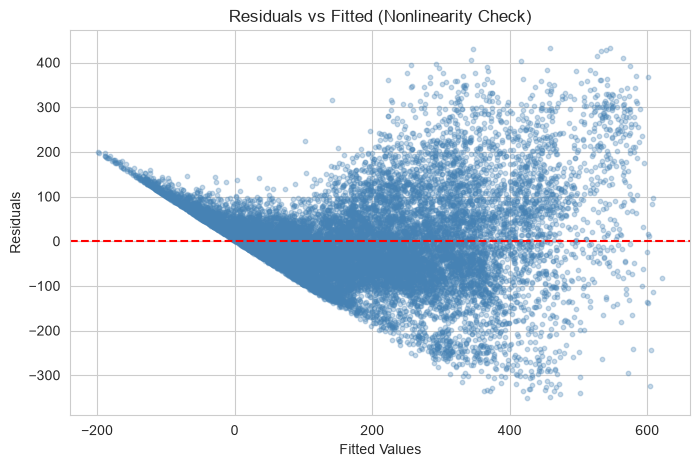

In [6]:
plt.figure(figsize=(8, 5))
plt.scatter(m1_clean.fittedvalues, m1_clean.resid, alpha=0.3, s=10, color='steelblue')
plt.axhline(y=0, color='red', linestyle='--')
plt.title('Residuals vs Fitted (Nonlinearity Check)')
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.show()

### Interpretation
**Author**: Kok Wai Ying 
<!-- Document rationale for dropped variables -->
The plot shows a clear U-shaped curvature in the residuals, rather than a random scatter. This systematic pattern is a strong indicator of nonlinearity, suggesting that the model is missing important nonlinear terms and cannot capture the true relationship between the predictors and the target. On the right side of the plot, as the fitted value increase from 200 to 600, the vertical spread of the residual gets wider and wider looking like a funnel shape. The two shape proves both nonlinearity and heteroscedasticty (non constant variance)

## 6. Nonlinearity Diagnostics (Residuals by Hour x Working Day)
*Code: Generated by AI Assistant*

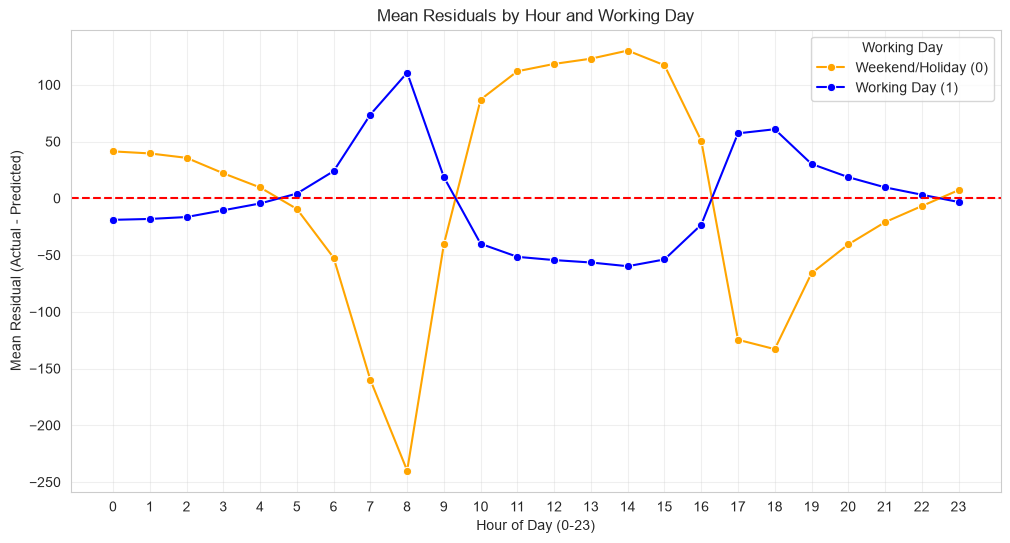

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. We need to extract the 'hour' back from the dummy variables
# base_df has columns hr_1, hr_2... hr_23. 
# If all are 0, it means it's Hour 0.
hr_cols = [c for c in base_df.columns if c.startswith('hr_')]
base_df['hour'] = base_df[hr_cols].idxmax(axis=1).str.replace('hr_', '').astype(int)
base_df.loc[base_df[hr_cols].sum(axis=1) == 0, 'hour'] = 0

# 2. Get the residuals from our clean model
base_df['residuals'] = m1_clean.resid

# 3. Create the plot
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=base_df, 
    x='hour', 
    y='residuals', 
    hue='workingday', 
    errorbar=None, 
    marker='o',
    palette={0: 'orange', 1: 'blue'}
)

plt.axhline(0, color='red', linestyle='--')
plt.title('Mean Residuals by Hour and Working Day')
plt.xlabel('Hour of Day (0-23)')
plt.ylabel('Mean Residual (Actual - Predicted)')
plt.xticks(range(0, 24))
plt.legend(title='Working Day', labels=['Weekend/Holiday (0)', 'Working Day (1)'])
plt.grid(True, alpha=0.3)
plt.show()

### Interpretation
**Author**: Kok Wai Ying 
<!-- Document rationale for dropped variables -->
If one hourly profile fit both day types, both lines would stay near zero. They don’t, and they move in opposite directions. During the commuter peaks (8 AM and 5-6 PM), M1 under-predicts working days (about +110 and +60) and over-predicts non-working days (about -240 and -130). At midday (10 AM-3 PM) the pattern reverses: non-working days are under-predicted (about +90 to +130) and working days over-predicted (about -40 to -60).

This indicates that the daily demand curve depends on the day type, which an additive model cannot represent. It motivates the hr × workingday interaction in Notebook 04. 

## 7. Added Variable Plots (Continuous Predictor)
*Code: Generated by AI Assistant*

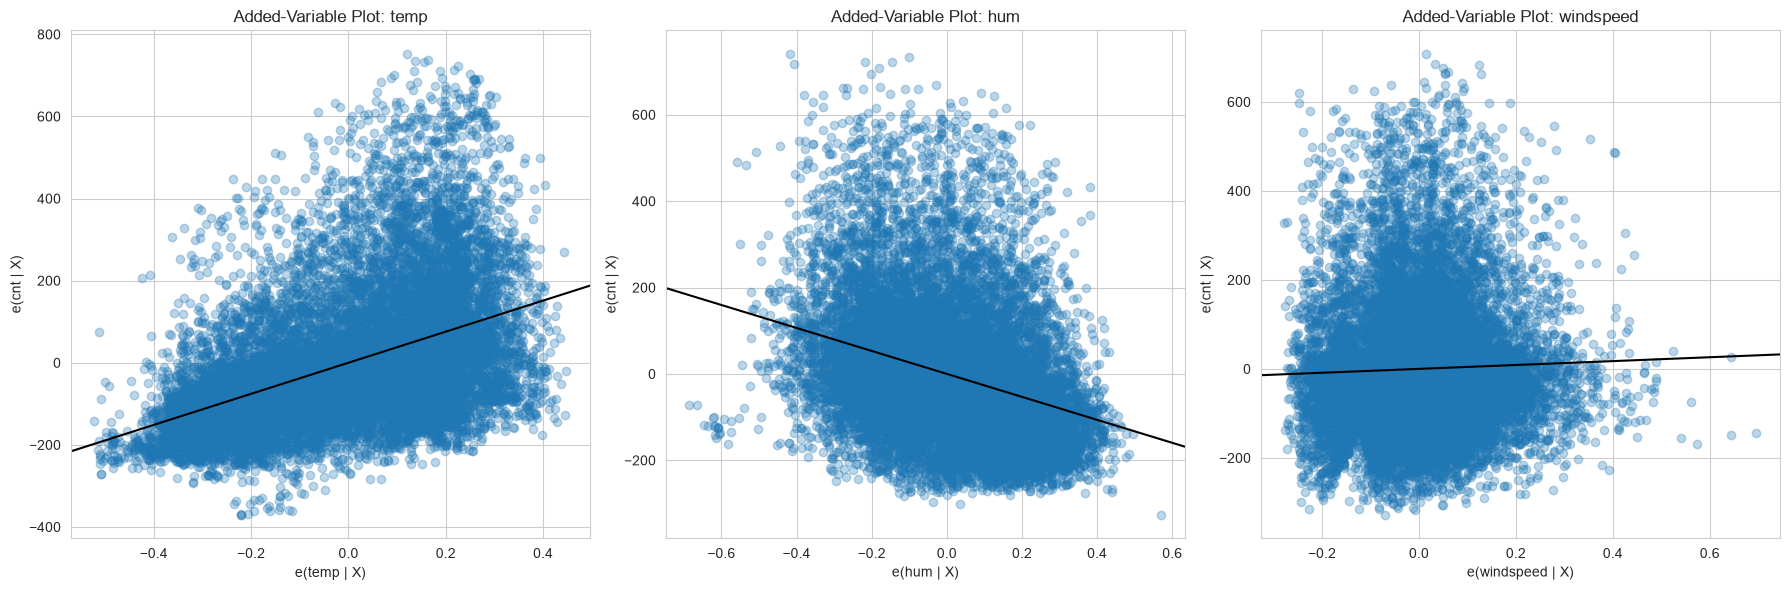

In [8]:
import statsmodels.graphics.regressionplots as plots
import matplotlib.pyplot as plt

# Set up a figure with 3 subplots side-by-side
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 1. Added-Variable Plot for Temperature
# We pass the clean model (m1_clean), the variable of interest ('temp'), and the axes
plots.plot_partregress(
    endog='cnt', 
    exog_i='temp', 
    exog_others=['hum', 'windspeed'], 
    data=base_df, 
    ax=axes[0], 
    obs_labels=False, # Hides the row numbers so the plot isn't cluttered
    alpha=0.3,
    result_object=False
)
axes[0].set_title('Added-Variable Plot: temp')

# 2. Added-Variable Plot for Humidity
plots.plot_partregress(
    endog='cnt', 
    exog_i='hum', 
    exog_others=['temp', 'windspeed'], 
    data=base_df, 
    ax=axes[1], 
    obs_labels=False, 
    alpha=0.3,
    result_object=False
)
axes[1].set_title('Added-Variable Plot: hum')

# 3. Added-Variable Plot for Windspeed
plots.plot_partregress(
    endog='cnt', 
    exog_i='windspeed', 
    exog_others=['temp', 'hum'], 
    data=base_df, 
    ax=axes[2], 
    obs_labels=False, 
    alpha=0.3,
    result_object=False
)
axes[2].set_title('Added-Variable Plot: windspeed')

plt.tight_layout()
plt.show()

### Interpretation
**Author**: Kok Wai Ying 
<!-- Document rationale for dropped variables -->
In general, as seen from the plot,  temp, hum and windspeed all has a highly non-linear relationship with cnt (bike demand). The straight regression line clearly miss the true curvature of all three variables.



## 8. Heteroskedasticity & Normality Diagnostic (Q-Q and Scale Location)
*Code: Generated by AI Assistant*

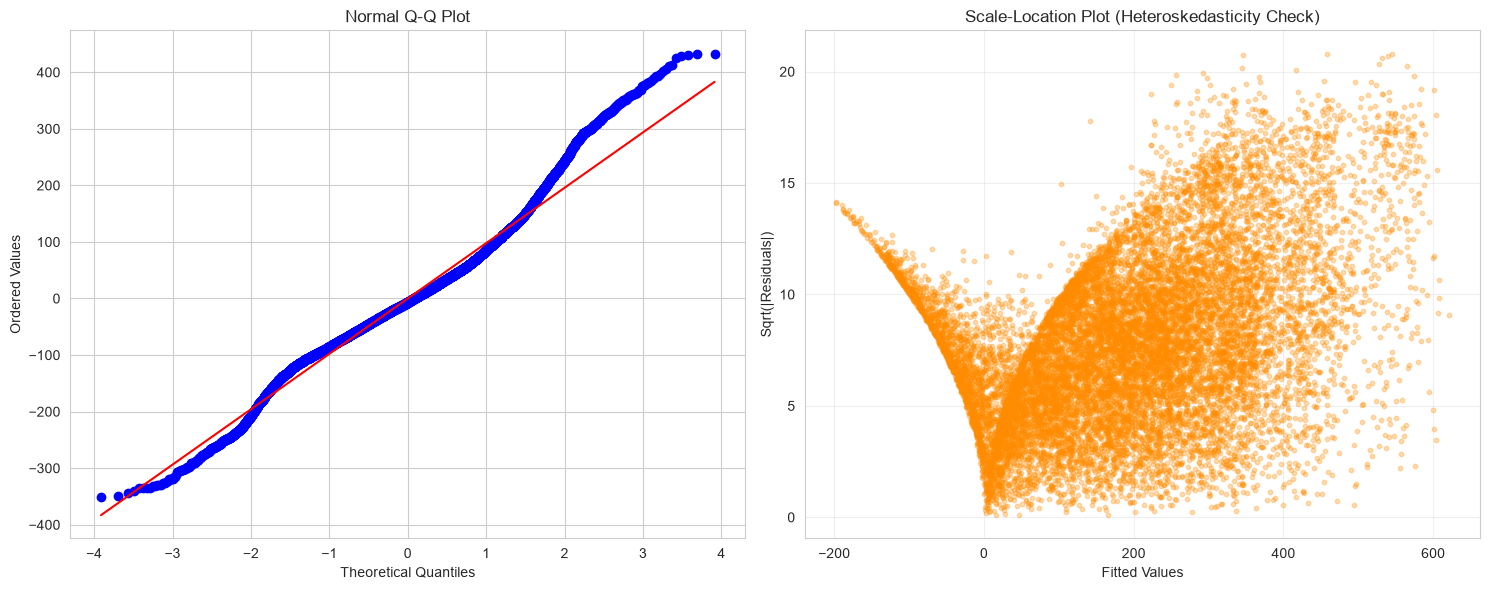

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Normal Q-Q Plot (Check for heavy tails / normality)
stats.probplot(m1_clean.resid, dist="norm", plot=axes[0])
axes[0].set_title('Normal Q-Q Plot')
axes[0].set_xlabel('Theoretical Quantiles')
axes[0].set_ylabel('Ordered Values')

# 2. Scale-Location Plot (Check for heteroskedasticity / variance funnel)
axes[1].scatter(m1_clean.fittedvalues, np.sqrt(np.abs(m1_clean.resid)), alpha=0.3, s=10, color='darkorange')
axes[1].set_title('Scale-Location Plot (Heteroskedasticity Check)')
axes[1].set_xlabel('Fitted Values')
axes[1].set_ylabel('Sqrt(|Residuals|)')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Interpretation
**Author**: Kok Wai Ying 
<!-- Document rationale for dropped variables -->
Normal Q-Q Plot: The residual forms a 'S' shape, this suggests a heavy tail and right skewness . The model fails to capture extreme outliers,especially the massive positive residuals during high demand hours. This violates the the OLS assumption of normally distributed errors.

Scale-location plot: The plot display a clear variance funnel. As the fitted value increase from 0 to 600+, the vertical spread of the residual expands dramatically. This confirms servere heteroskedasticity. This suggests that the model's error are much larger during high demand hours than low demand hours. 

The heteroskedasticity and heavy tails indicates that a linear OLS model on raw count data is inappropriate. 



## 9. Negative Prediction Violations
*Code: Generated by AI Assistant*

In [10]:
# Count negative predictions
negative_preds = (m1_clean.fittedvalues < 0).sum()
total_preds = len(m1_clean.fittedvalues)

print(f"Total predictions: {total_preds}")
print(f"Negative predictions (impossible demand): {negative_preds} ({(negative_preds/total_preds)*100:.2f}%)")

Total predictions: 15211
Negative predictions (impossible demand): 1597 (10.50%)


### Interpretation
**Author**: Kok Wai Ying 
<!-- Document rationale for dropped variables -->
The linear OLS model generated 10.50% of negative predictions.  In this baseline model, categorical features are dummy-encoded using Midnight (Hour 0) as the reference baseline. Consequently, a negative coefficient like Beta_hr1 = -17.60 does not imply negative bike rentals. It simply indicates that expected demand at 1:00 AM is 18 units lower on average compared to midnight, holding all weather and calendar variables constant. Overall model predictions are calculated by summing the intercept, weather contributions, and time offsets. Because standard Ordinary Least Squares (OLS) fits unbounded continuous numbers rather than non-negative counts, negative predictions can occasionally occur during extreme off-peak hours. This is a known structural constraint of linear regression on raw count data, which we address in subsequent iterations through target log-transformations.

## 10. Outlier Screening & Date-based Adjudication 
*Code: Generated by AI Assistant*

In [11]:
# Calculate Cook's Distance
influence = m1_clean.get_influence()
cooks_d = influence.cooks_distance[0]

# Flag points where Cook's D > 4/N
threshold = 4 / len(base_df)
outliers = base_df[cooks_d > threshold].copy()
outliers['cooks_d'] = cooks_d[cooks_d > threshold]

print(f"Number of outliers (Cook's D > 4/N): {len(outliers)}")
print("\nTop 5 dates with the most outliers:")
print(outliers['dteday'].value_counts().head(5))

Number of outliers (Cook's D > 4/N): 954

Top 5 dates with the most outliers:
dteday
2012-09-08    10
2011-07-04     9
2012-04-21     9
2012-07-04     9
2012-09-23     9
Name: count, dtype: int64


In [12]:
# 1. Get the top 5 dates with the most outliers
top_dates = outliers['dteday'].value_counts().head(5).index

# 2. Filter the original dataset for these dates
# (We use base_df to get the dummy columns, and train_raw/train_df to get the readable units if needed)
investigation_df = base_df[base_df['dteday'].isin(top_dates)].copy()

# 3. Select a few key columns to investigate
# We show the date, actual demand, weather, and calendar flags
cols_to_show = ['dteday', 'cnt', 'temp', 'hum', 'windspeed', 
                'weathersit_2', 'weathersit_3', 'holiday', 'workingday']

# If you want readable weather units (like temp in Celsius), you'd merge with Notebook 01's data
# But for now, the normalized dummies are fine to show the extreme values.

print("=== Profile of Top Outlier Dates ===")
print(investigation_df[cols_to_show].drop_duplicates(subset=['dteday']).to_string(index=False))

=== Profile of Top Outlier Dates ===
    dteday  cnt  temp  hum  windspeed  weathersit_2  weathersit_3  holiday  workingday
2011-07-04  140  0.64 0.83     0.1343             0             0        1           0
2012-04-21  142  0.52 0.77     0.2239             0             0        0           0
2012-07-04  159  0.68 0.79     0.0896             0             0        1           0
2012-09-08  150  0.66 0.89     0.2537             0             0        0           0
2012-09-23  180  0.62 0.38     0.2537             0             0        0           0


### Interpretation
**Author**: Kok Wai Ying 
<!-- Document rationale for dropped variables -->
On closer inspection of the top outlier dates, an interesting pattern emerges: None of the dates features extreme weather. In fact,  weathersit_2 and weahtersit_3 are 0 (Clear weather) for all of them. Only 2011-07-04 is a holiday (Independence Day). 

These dates were flagged because M1 fits non-working days poorly, not because the data is erroneous. We therefore keep the rows and expect the hour × working-day interaction in Notebook 04 to reduce these errors.

## 10. Shared CV Evaluation
*Code: Generated by AI Assistant*

In [13]:
import numpy as np
import statsmodels.api as sm
from sklearn.base import BaseEstimator, RegressorMixin

# 1. Same OLS wrapper as before (adds the constant inside)
class OLSWrapper(BaseEstimator, RegressorMixin):
    def __init__(self):
        self.model = None

    def fit(self, X, y):
        X_const = sm.add_constant(X, has_constant='add')
        self.model = sm.OLS(y, X_const).fit()
        return self

    def predict(self, X):
        X_const = sm.add_constant(X, has_constant='add')
        return self.model.predict(X_const)

# 2. Score each expanding-window fold on the count scale (M1 is fitted on raw cnt)
fold_mse, fold_mae = [], []
for tr, va in cv_splitter.split(base_df):
    est = OLSWrapper().fit(X_clean.iloc[tr], y.iloc[tr])
    pred = np.asarray(est.predict(X_clean.iloc[va]))
    err = y.iloc[va].to_numpy() - pred
    fold_mse.append(np.mean(err ** 2))
    fold_mae.append(np.mean(np.abs(err)))

fold_mse, fold_mae = np.array(fold_mse), np.array(fold_mae)

# 3. Summarise with the Notebook 02/04/05/06 definition:
#    CV RMSE = sqrt(mean fold MSE), SE = SD(ddof=1) / sqrt(k)
k = len(fold_mse)
cv_mse = fold_mse.mean()
se_mse = fold_mse.std(ddof=1) / np.sqrt(k)
cv_rmse = np.sqrt(cv_mse)
se_rmse = se_mse / (2 * cv_rmse)          # delta method, as in Notebooks 05/06
cv_mae = fold_mae.mean()
se_mae = fold_mae.std(ddof=1) / np.sqrt(k)

print("=== Baseline Model (M1) CV Results ===")
print(f"Mean MSE:  {cv_mse:.2f}  (SE: {se_mse:.2f})")
print(f"CV RMSE:   {cv_rmse:.2f}  (SE: {se_rmse:.2f})   [sqrt of mean fold MSE]")
print(f"Mean MAE:  {cv_mae:.2f}  (SE: {se_mae:.2f})")

=== Baseline Model (M1) CV Results ===
Mean MSE:  17125.20  (SE: 1882.65)
CV RMSE:   130.86  (SE: 7.19)   [sqrt of mean fold MSE]
Mean MAE:  97.89  (SE: 6.88)


### Interpretation
**Author**: Kok Wai Ying 
<!-- Document rationale for dropped variables -->
The baseline M1 model was evaluated across the shared 8-fold expanding-window CV (Feb–Sep 2012). 

- Out-of-sample error: The model achieved a mean MSE of 17125.20 (SE = 1882.65). 
- Model Accuracy: Given that the average hourly bike rental demand is ~185 bikes, an RMSE of 130.86 means the model's predictions are off by an enormous margin on unseen data. 
- Conclusion: This poor cross-validated performance confirms that the structural flaws diagnosed (heteroskedasticity, missing nonlinearity, and ignored interactions) severely degrade the model's ability to generalize to future months. This establishes a high benchmark that the remedied models in Notebook 04 must significantly beat.

## 10. Catalog of Diagnosed Mistakes to Fix in Notebook 04
**Author**: Kok Wai Ying

Based on the OLS summary, CV evaluation, and diagnostic plots, the baseline M1 model exhibits the following severe structural failures:

1. Ignored Interaction Effects (Hour × Working Day): The model applies the same hourly profile to both weekdays and weekends. It fails to capture the 8 AM/5 PM commuter spikes on working days versus the midday leisure peak on weekends.
2. Unmodeled Nonlinearity: The residuals vs. fitted plot shows a clear U-shape, and the added-variable plots confirm that temp, hum, and windspeed all have non-linear threshold effects. 
3. Heteroskedasticity: The Scale-Location plot shows a massive variance funnel. As demand increases, the error variance expands dramatically, violating OLS assumptions.
4. Non-Normal Residuals: The Q-Q plot shows heavy tails (an "S" shape), meaning the residuals are not normally distributed.
5. Negative Demand Predictions: The model predicts impossible negative bike rentals during the overnight hours due to the nature of linear planes.
6. Rank Deficiency (Remedied): workingday was dropped to resolve perfect multicollinearity with weekday and holiday.

Plan for Notebook 04: We will remedy these failures by introducing hour × workingday interaction terms, adding polynomial terms for weather variables, and applying a log-transformation to fix the negative predictions and heteroskedasticity.